
# Network Traffic Cybersecurity Analysis
## Data Analysis

 Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, mean_absolute_error,
                             mean_squared_error, r2_score)
from sklearn.preprocessing import LabelEncoder, StandardScaler

import warnings
warnings.filterwarnings('ignore')

Load Data

In [2]:
df = pd.read_csv('Dataset2_odd_students.csv')
print(f"Dataset shape: {df.shape}")
df.head(10)

Dataset shape: (6000, 19)


,packet_session_id,protocol,device_type,vpn_status,region,login_attempts,failed_logins,bytes_sent,bytes_received,packet_rate,connection_count,tcp_flags,port_number,session_retries,signal_strength,privilege_level,anomaly_score,avg_packet_size,attack_category
0,P000000,TCP,Workstation,On,APAC,0,6,3735.701997,7083.530344,184.514770,7,FIN,3389,0,-71.345111,user,0.117355,332.602010,Benign
1,P000001,TCP,Workstation,Off,EU,1,2,6140.866808,4382.336675,155.062604,5,ACK,110,1,-44.351883,user,0.238888,314.553416,Benign
2,P000002,TCP,Workstation,Off,US,3,0,4714.244672,6979.428832,125.959250,4,FIN,80,0,-64.475005,user,0.123961,266.942545,Benign
3,P000003,UDP,Server,Off,APAC,2,0,2987.854450,2715.307765,88.444309,3,FIN,110,1,-48.033202,guest,0.462781,259.362639,BruteForce
4,P000004,UDP,IoT,Off,US,1,5,5021.324823,4858.666310,153.385483,2,SYN-ACK,110,2,-65.320352,user,0.185527,293.294721,BruteForce
5,P000005,TCP,Workstation,On,EU,3,1,5611.170345,7618.088822,115.158658,3,SYN,110,0,-68.288010,admin,0.570801,284.647177,BruteForce
6,P000006,tcp,Workstation,Off,EU,6,2,3140.607112,5539.065998,145.283235,5,SYN,21,1,-64.918360,guest,0.344138,305.526912,Benign
7,P000007,NaN,Mobile,On,APAC,4,0,5369.040024,7248.335284,127.831649,7,SYN,110,0,-57.737418,user,0.135030,318.689917,Benign
8,P000008,ICMP,IoT,Off,US,3,1,33385.813113,9726.207835,138.591434,10,SYN-ACK,53,3,-59.282052,user,0.434628,346.286492,Benign
9,P000009,UDP,Workstation,Off,EU,2,2,1486.056410,5089.932042,104.080559,5,ACK,21,3,-65.828516,user,0.552794,216.432037,Benign


In [3]:
df.protocol.unique()

array(['TCP', 'UDP', 'tcp', nan, 'ICMP', 'udp'], dtype=object)

Data Understanding & Exploration

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   packet_session_id  6000 non-null   object 
 1   protocol           5580 non-null   object 
 2   device_type        6000 non-null   object 
 3   vpn_status         6000 non-null   object 
 4   region             6000 non-null   object 
 5   login_attempts     6000 non-null   int64  
 6   failed_logins      6000 non-null   int64  
 7   bytes_sent         6000 non-null   float64
 8   bytes_received     5580 non-null   float64
 9   packet_rate        6000 non-null   float64
 10  connection_count   6000 non-null   int64  
 11  tcp_flags          6000 non-null   object 
 12  port_number        6000 non-null   int64  
 13  session_retries    6000 non-null   int64  
 14  signal_strength    5580 non-null   float64
 15  privilege_level    6000 non-null   object 
 16  anomaly_score      6000 

In [5]:
df.describe()

,login_attempts,failed_logins,bytes_sent,bytes_received,packet_rate,connection_count,port_number,session_retries,signal_strength,anomaly_score,avg_packet_size
count,6000.000000,6000.00000,6000.000000,5580.000000,6000.000000,6000.000000,6000.000000,6000.000000,5580.000000,6000.000000,6000.000000
mean,1.986167,1.01300,5244.930668,6030.812597,125.406064,5.007500,464.325667,0.990000,-60.001938,0.288818,291.962610
std,1.403913,1.00565,3148.811236,2024.969118,66.673500,2.231802,1022.536272,0.987453,9.956151,0.161198,23.270255
min,0.000000,0.00000,100.000000,100.000000,10.000000,0.000000,21.000000,0.000000,-96.498666,0.004041,198.964322
25%,1.000000,0.00000,3985.123437,4698.079531,99.429233,3.000000,25.000000,0.000000,-66.730775,0.164258,276.480544
50%,2.000000,1.00000,4971.300665,6036.927406,120.364024,5.000000,80.000000,1.000000,-59.985307,0.267198,291.736995
75%,3.000000,2.00000,6017.944743,7403.422659,140.340118,6.000000,143.000000,2.000000,-53.391908,0.395506,307.606272
max,8.000000,6.00000,53602.250239,14261.024735,1068.619903,16.000000,3389.000000,6.000000,-25.848112,0.851668,375.361722


In [6]:
for col in df.columns:
    print(f"{col:25s}: {df[col].nunique()} unique | sample: {df[col].dropna().unique()[:5]}")

packet_session_id        : 6000 unique | sample: ['P000000' 'P000001' 'P000002' 'P000003' 'P000004']
protocol                 : 5 unique | sample: ['TCP' 'UDP' 'tcp' 'ICMP' 'udp']
device_type              : 4 unique | sample: ['Workstation' 'Server' 'IoT' 'Mobile']
vpn_status               : 2 unique | sample: ['On' 'Off']
region                   : 4 unique | sample: ['APAC' 'EU' 'US' 'ME']
login_attempts           : 9 unique | sample: [0 1 3 2 6]
failed_logins            : 7 unique | sample: [6 2 0 5 1]
bytes_sent               : 5997 unique | sample: [3735.7019966  6140.86680825 4714.24467183 2987.8544502  5021.32482319]
bytes_received           : 5573 unique | sample: [7083.53034412 4382.33667462 6979.42883209 2715.3077653  4858.66631043]
packet_rate              : 5999 unique | sample: [184.51477016 155.0626045  125.95924971  88.44430939 153.38548319]
connection_count         : 16 unique | sample: [7 5 4 3 2]
tcp_flags                : 4 unique | sample: ['FIN' 'ACK' 'SYN-ACK' 'SY

In [7]:
missing = df.isnull().sum()
pct = (missing / len(df) * 100).round(2)
pd.DataFrame({'Missing Count': missing, 'Missing %': pct})[missing > 0]

,Missing Count,Missing %
protocol,420,7.0
bytes_received,420,7.0
signal_strength,420,7.0


In [8]:
# Check if the same rows are missing across all three affected columns
overlap = df[['protocol','bytes_received','signal_strength']].isnull().all(axis=1).sum()
any_missing = df[['protocol','bytes_received','signal_strength']].isnull().any(axis=1).sum()
print(f"Rows missing in ALL three columns:  {overlap}")
print(f"Rows missing in ANY of three columns: {any_missing}")

Rows missing in ALL three columns:  2
Rows missing in ANY of three columns: 1160


In [9]:
print("attack_category distribution:")
print(df['attack_category'].value_counts())
print()
print("Percentage:")
print((df['attack_category'].value_counts(normalize=True)*100).round(2))

attack_category distribution:
attack_category
Benign        4161
BruteForce    1839
Name: count, dtype: int64

Percentage:
attack_category
Benign        69.35
BruteForce    30.65
Name: proportion, dtype: float64


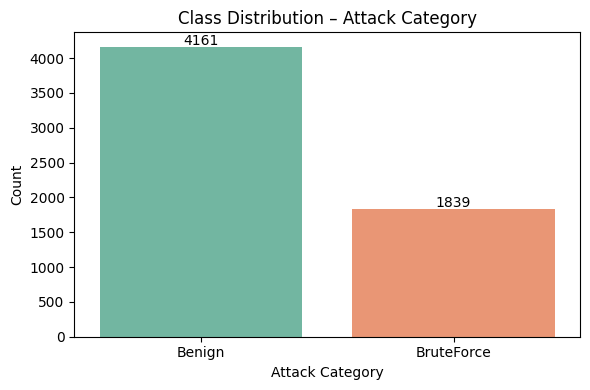

In [10]:
plt.figure(figsize=(6,4))
ax = sns.countplot(x='attack_category', data=df, palette='Set2',
                   order=df['attack_category'].value_counts().index)
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x()+p.get_width()/2, p.get_height()+30), ha='center')
plt.title('Class Distribution – Attack Category')
plt.xlabel('Attack Category'); plt.ylabel('Count')
plt.tight_layout(); plt.show()

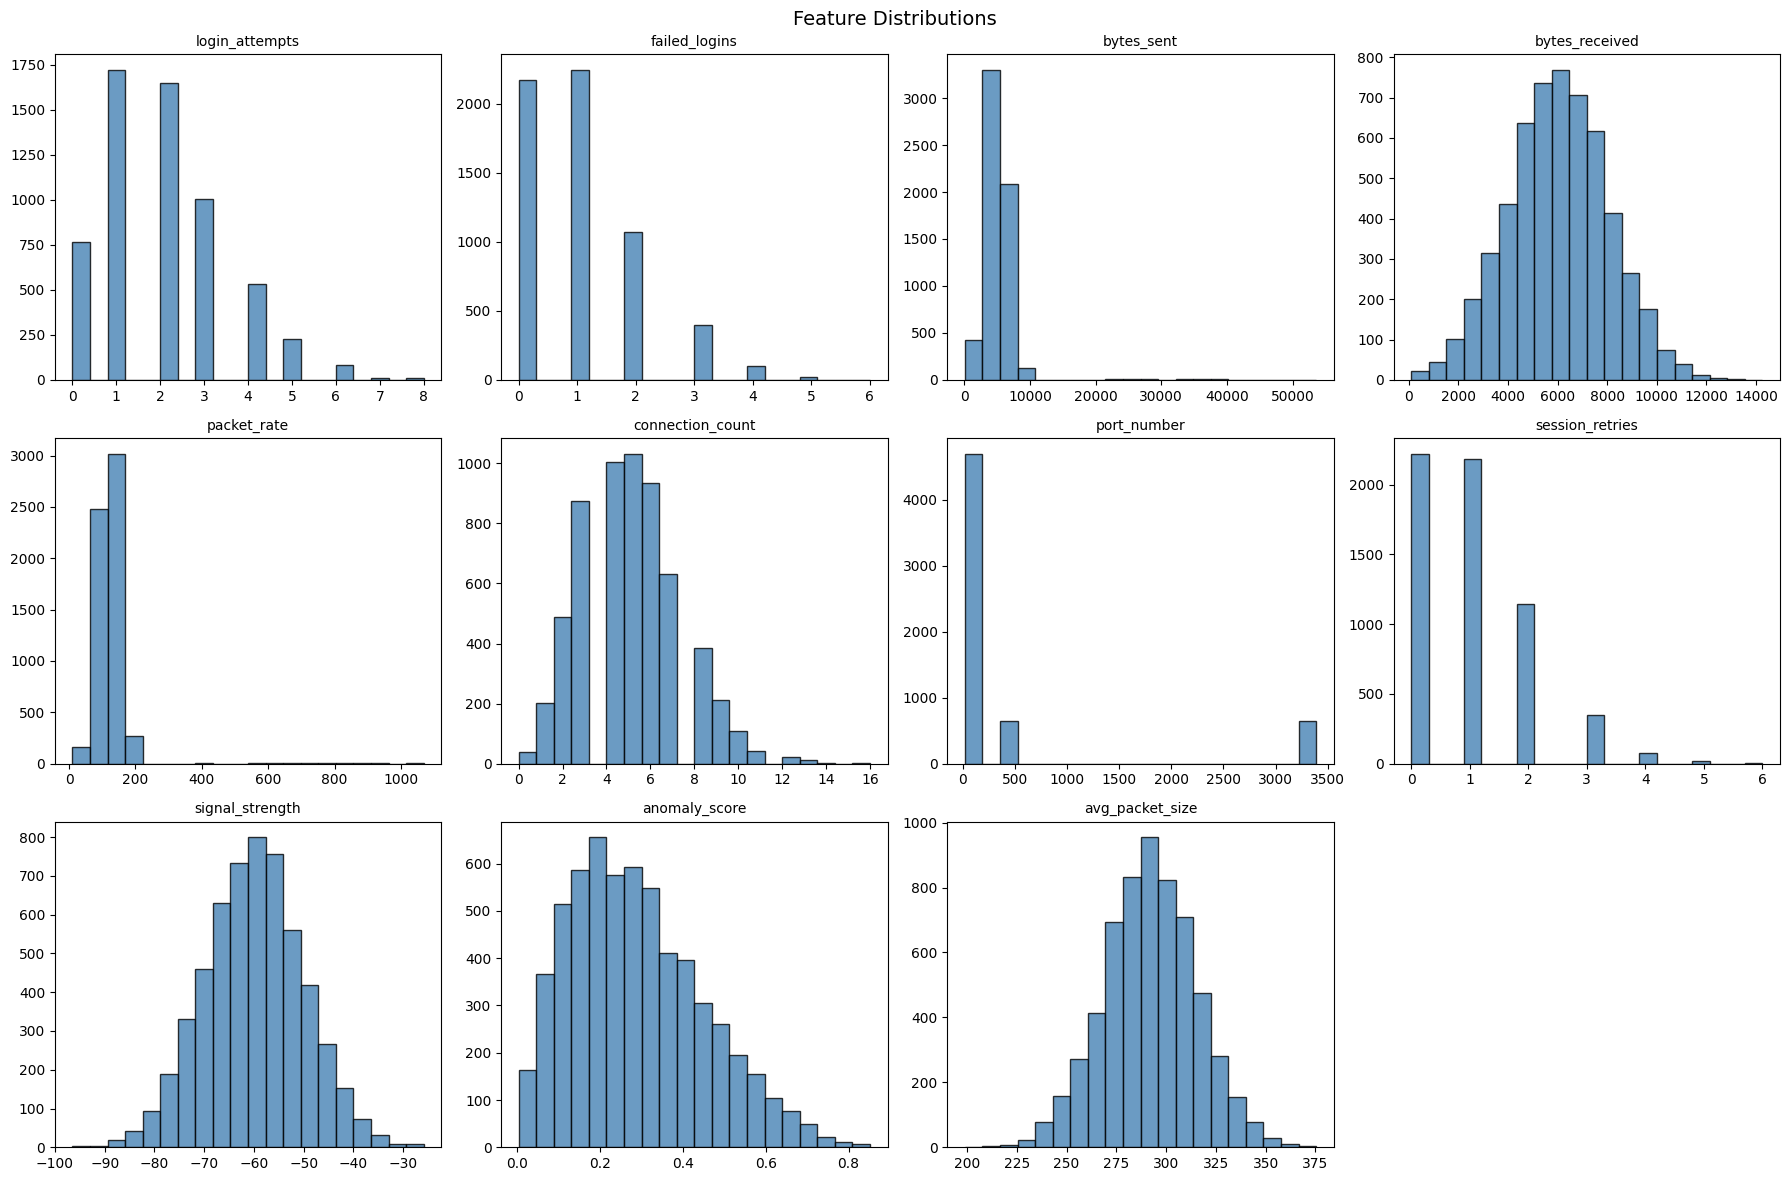

In [11]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
fig, axes = plt.subplots(3, 4, figsize=(18, 12))
axes = axes.flatten()
for i, col in enumerate(numeric_cols):
    axes[i].hist(df[col].dropna(), bins=20, edgecolor='black', color='steelblue', alpha=0.8)
    axes[i].set_title(col, fontsize=10)
for j in range(i+1, len(axes)): axes[j].set_visible(False)
plt.suptitle('Feature Distributions', fontsize=14); plt.tight_layout(); plt.show()

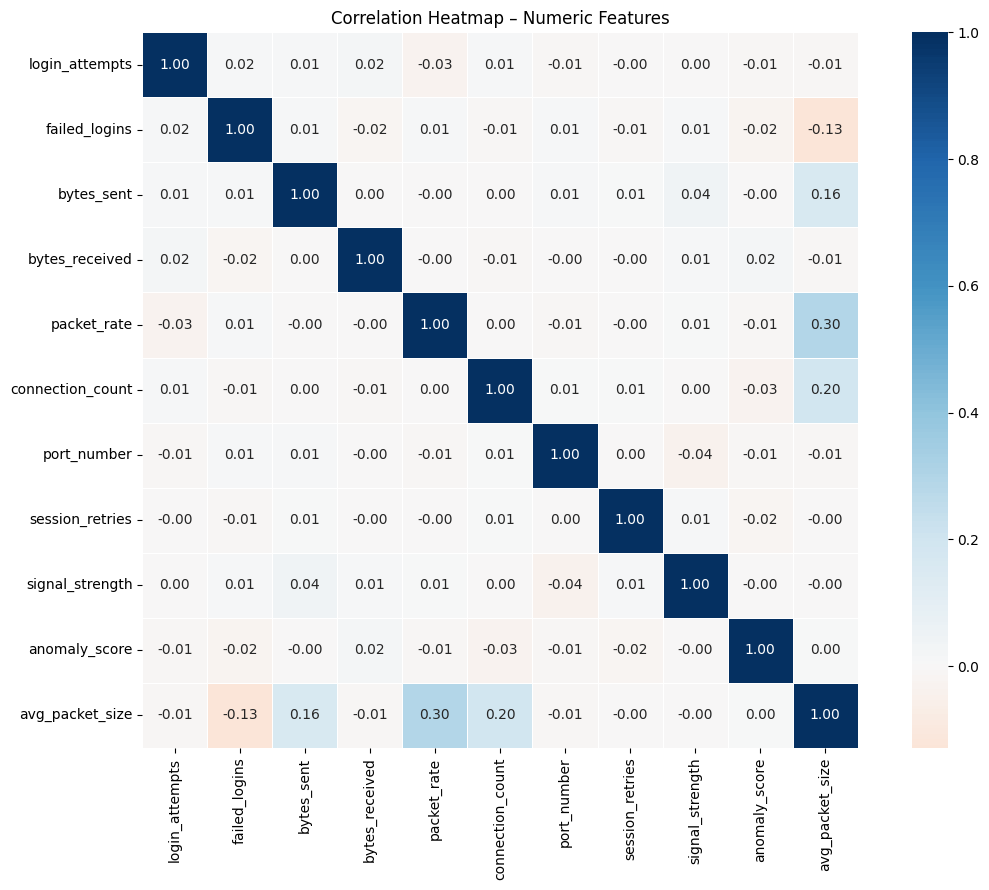

In [12]:
plt.figure(figsize=(12, 9))
corr = df[numeric_cols].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu', center=0, square=True, linewidths=0.5)
plt.title('Correlation Heatmap – Numeric Features'); plt.tight_layout(); plt.show()

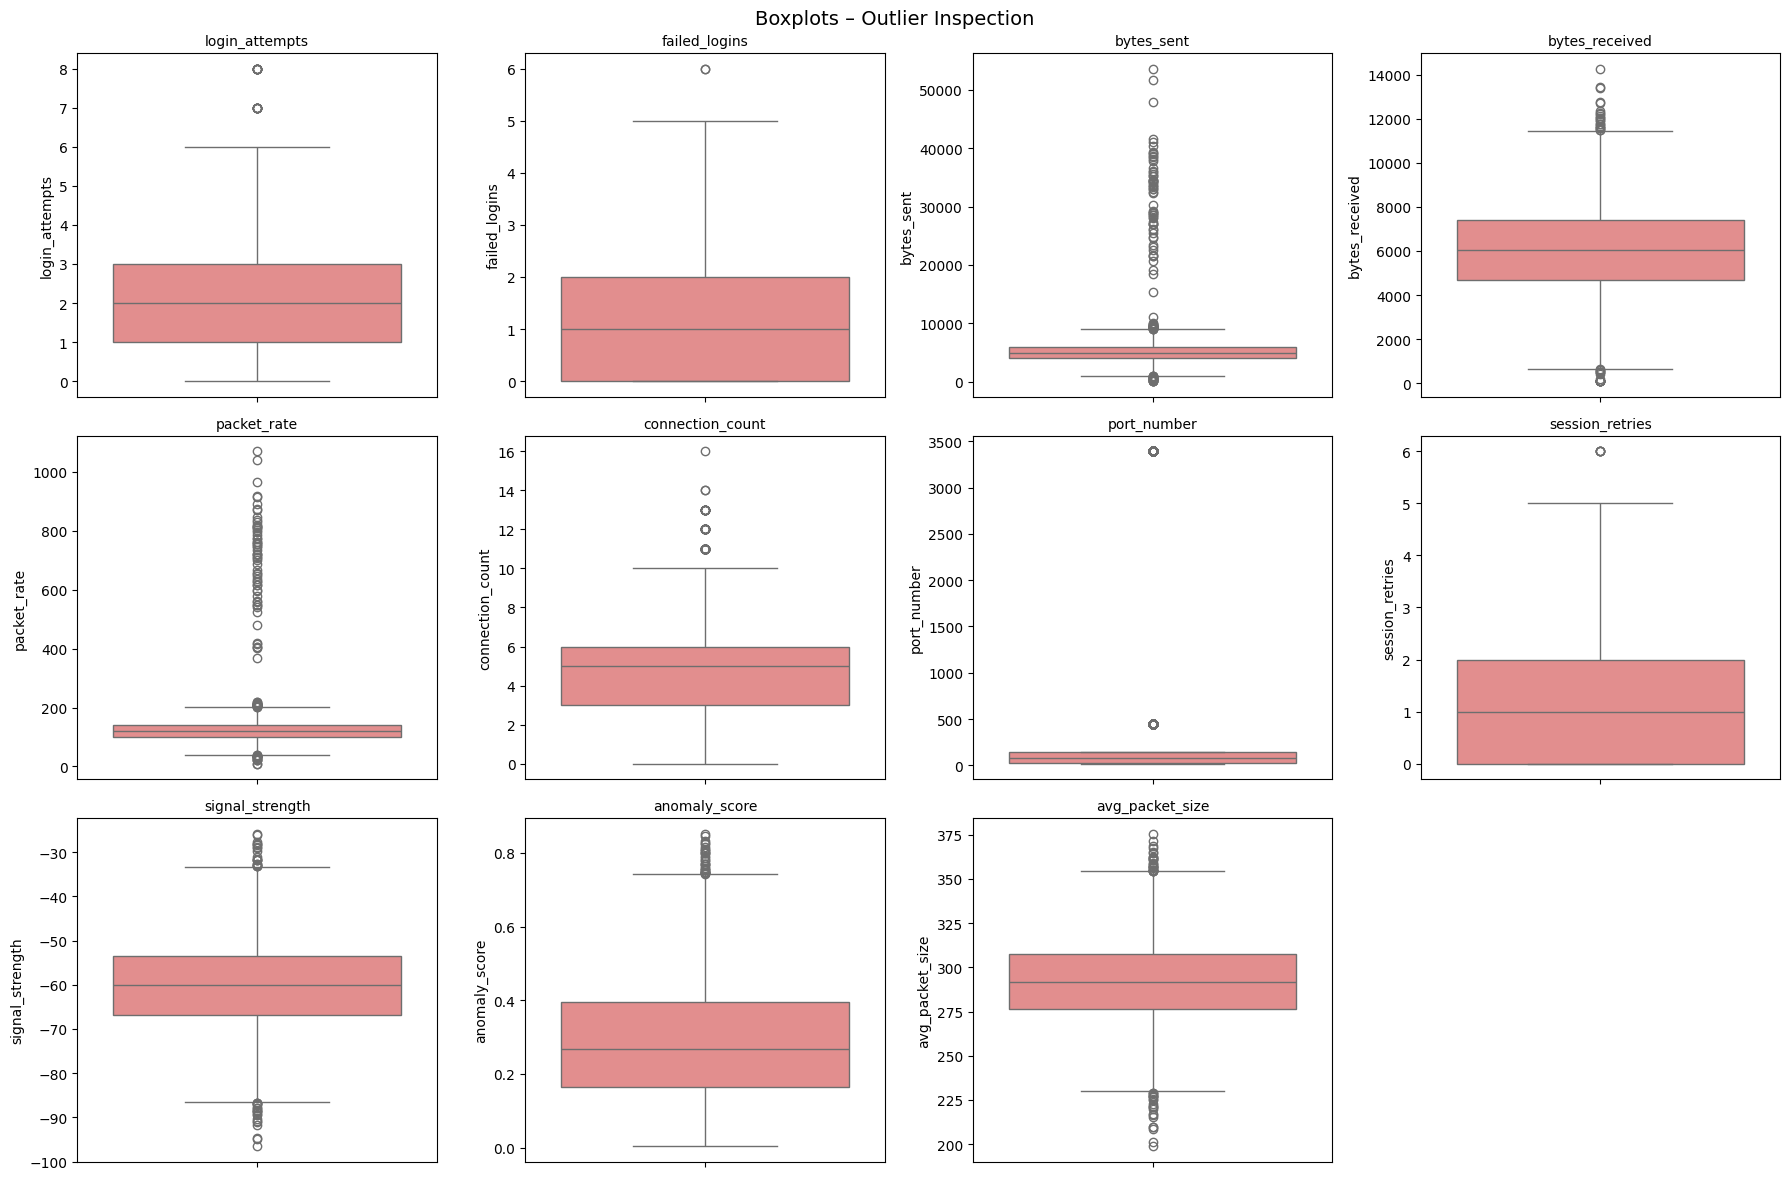

In [13]:
fig, axes = plt.subplots(3, 4, figsize=(18, 12))
axes = axes.flatten()
for i, col in enumerate(numeric_cols):
    sns.boxplot(y=df[col], ax=axes[i], color='lightcoral')
    axes[i].set_title(col, fontsize=10)
for j in range(i+1, len(axes)): axes[j].set_visible(False)
plt.suptitle('Boxplots – Outlier Inspection', fontsize=14); plt.tight_layout(); plt.show()

Data Preparation

In [14]:
# Work on a clean copy
df_clean = df.copy()
df_clean.drop(columns=['packet_session_id'], inplace=True)
print("Dropped packet_session_id – not a predictive feature.")
print("Remaining columns:", list(df_clean.columns))

Dropped packet_session_id – not a predictive feature.
Remaining columns: ['protocol', 'device_type', 'vpn_status', 'region', 'login_attempts', 'failed_logins', 'bytes_sent', 'bytes_received', 'packet_rate', 'connection_count', 'tcp_flags', 'port_number', 'session_retries', 'signal_strength', 'privilege_level', 'anomaly_score', 'avg_packet_size', 'attack_category']


In [15]:
# Standardize casing to Uppercase
df_clean['protocol'] = df['protocol'].str.upper()

In [16]:
df_clean.protocol.unique()

array(['TCP', 'UDP', nan, 'ICMP'], dtype=object)

In [17]:
# Handle missing values
df_clean.loc[:, 'protocol'] = df_clean['protocol'].fillna(df_clean['protocol'].mode()[0])
df_clean.loc[:, 'bytes_received'] = df_clean['bytes_received'].fillna(df_clean['bytes_received'].median())
df_clean.loc[:, 'signal_strength'] = df_clean['signal_strength'].fillna(df_clean['signal_strength'].median())

print("Missing values after imputation:")
print(df_clean.isnull().sum())

Missing values after imputation:
protocol            0
device_type         0
vpn_status          0
region              0
login_attempts      0
failed_logins       0
bytes_sent          0
bytes_received      0
packet_rate         0
connection_count    0
tcp_flags           0
port_number         0
session_retries     0
signal_strength     0
privilege_level     0
anomaly_score       0
avg_packet_size     0
attack_category     0
dtype: int64


In [18]:
# Label encode all categorical columns except target
cat_cols = ['protocol','device_type','vpn_status','region','tcp_flags','privilege_level']
le_dict = {}
for col in cat_cols:
    le = LabelEncoder()
    df_clean[col] = le.fit_transform(df_clean[col].astype(str))
    le_dict[col] = le
print("Encoded columns:", cat_cols)

Encoded columns: ['protocol', 'device_type', 'vpn_status', 'region', 'tcp_flags', 'privilege_level']


In [19]:
# Encode target
le_target = LabelEncoder()
df_clean['attack_category_enc'] = le_target.fit_transform(df_clean['attack_category'])
print("Target encoding:", dict(zip(le_target.classes_, le_target.transform(le_target.classes_))))

Target encoding: {'Benign': np.int64(0), 'BruteForce': np.int64(1)}


In [20]:
# Feature Engineering
df_clean['failed_login_ratio'] = df_clean['failed_logins'] / (df_clean['login_attempts'] + 1)

df_clean['anomaly_per_packet'] = df_clean['anomaly_score'] / (df_clean['packet_rate'] + 1)

print("New features created: failed_login_ratio, anomaly_per_packet")
df_clean[['failed_login_ratio','anomaly_per_packet','attack_category']].describe().round(4)

New features created: failed_login_ratio, anomaly_per_packet


,failed_login_ratio,anomaly_per_packet
count,6000.0000,6000.0000
mean,0.4312,0.0026
std,0.5405,0.0019
min,0.0000,0.0000
25%,0.0000,0.0013
50%,0.3333,0.0022
75%,0.6000,0.0034
max,6.0000,0.0653


In [21]:
# StandardScaler — zero mean, unit variance
feature_cols = [c for c in df_clean.columns if c not in ['attack_category','attack_category_enc']]
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(df_clean[feature_cols]), columns=feature_cols)
print(f"Scaled {len(feature_cols)} features. NaNs remaining: {X_scaled.isnull().sum().sum()}")

Scaled 19 features. NaNs remaining: 0


Classification – Predicting `attack_category`
Target: Benign (0) vs BruteForce (1)

In [22]:
y_clf = df_clean['attack_category_enc'].values
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_scaled, y_clf, test_size=0.2, random_state=42, stratify=y_clf)


Baseline – Decision Tree (default parameters)

=== Decision Tree (Baseline) ===
              precision    recall  f1-score   support

      Benign       0.69      0.66      0.68       832
  BruteForce       0.31      0.35      0.33       368

    accuracy                           0.56      1200
   macro avg       0.50      0.50      0.50      1200
weighted avg       0.58      0.56      0.57      1200



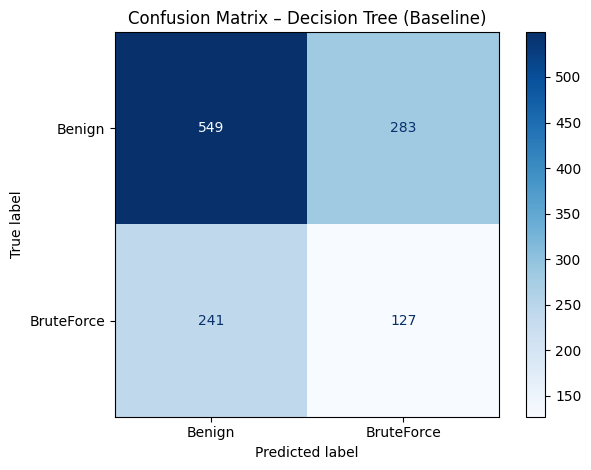

5-Fold CV F1: [0.575  0.5439 0.562  0.5667 0.556 ] | Mean: 0.5607 | Std: 0.0105


In [23]:
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train_c, y_train_c)
y_pred_dt = dt.predict(X_test_c)

print("=== Decision Tree (Baseline) ===")
print(classification_report(y_test_c, y_pred_dt, target_names=le_target.classes_))

cm_dt = confusion_matrix(y_test_c, y_pred_dt)
ConfusionMatrixDisplay(cm_dt, display_labels=le_target.classes_).plot(cmap='Blues')
plt.title('Confusion Matrix – Decision Tree (Baseline)')
plt.tight_layout(); plt.show()

cv_dt = cross_val_score(dt, X_scaled, y_clf, cv=cv, scoring='f1_weighted')
print(f"5-Fold CV F1: {cv_dt.round(4)} | Mean: {cv_dt.mean():.4f} | Std: {cv_dt.std():.4f}")

Improved – Random Forest (class_weight='balanced')

=== Random Forest (Improved) ===
              precision    recall  f1-score   support

      Benign       0.69      0.86      0.77       832
  BruteForce       0.29      0.13      0.18       368

    accuracy                           0.64      1200
   macro avg       0.49      0.49      0.47      1200
weighted avg       0.57      0.64      0.59      1200



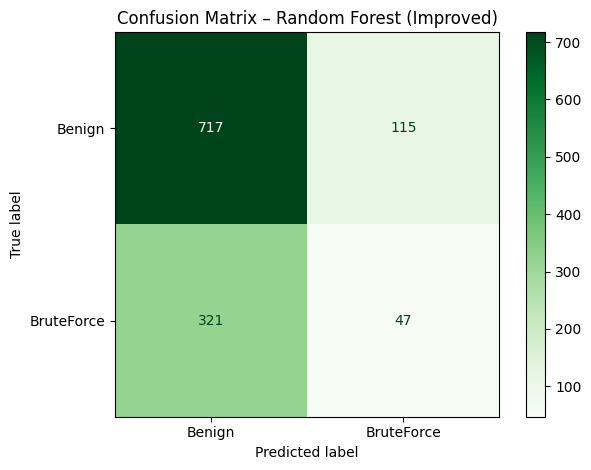

5-Fold CV F1: [0.5839 0.5742 0.6108 0.598  0.5852] | Mean: 0.5904 | Std: 0.0127


In [24]:
# class_weight='balanced' adjusts for 69/31 imbalance — prevents model always predicting Benign
rf = RandomForestClassifier(n_estimators=100, max_depth=10, class_weight='balanced', random_state=42)
rf.fit(X_train_c, y_train_c)
y_pred_rf = rf.predict(X_test_c)

print("=== Random Forest (Improved) ===")
print(classification_report(y_test_c, y_pred_rf, target_names=le_target.classes_))

cm_rf = confusion_matrix(y_test_c, y_pred_rf)
ConfusionMatrixDisplay(cm_rf, display_labels=le_target.classes_).plot(cmap='Greens')
plt.title('Confusion Matrix – Random Forest (Improved)')
plt.tight_layout(); plt.show()

cv_rf = cross_val_score(rf, X_scaled, y_clf, cv=cv, scoring='f1_weighted')
print(f"5-Fold CV F1: {cv_rf.round(4)} | Mean: {cv_rf.mean():.4f} | Std: {cv_rf.std():.4f}")

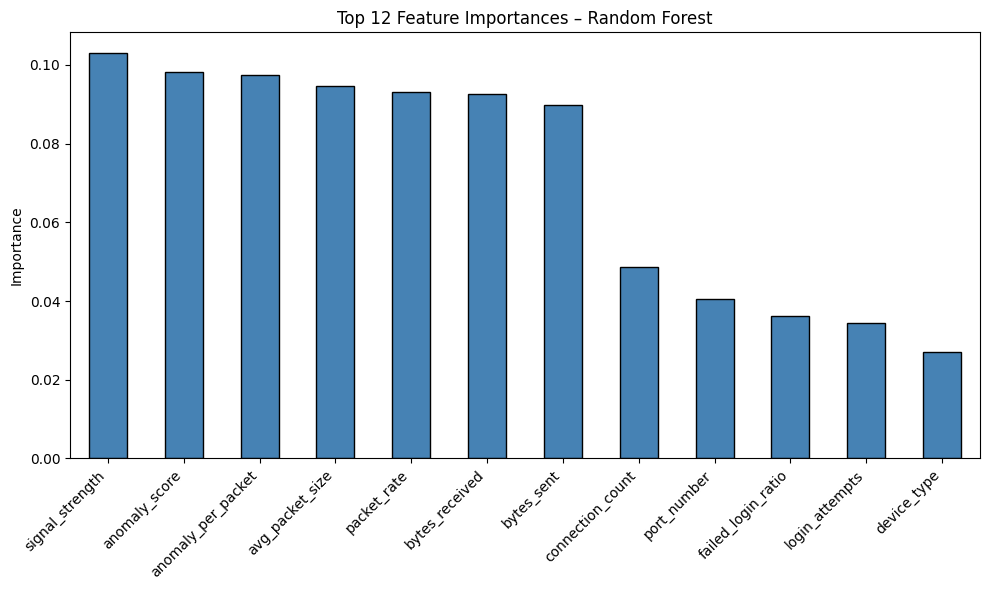

signal_strength       0.1031
anomaly_score         0.0981
anomaly_per_packet    0.0974
avg_packet_size       0.0947
packet_rate           0.0931
bytes_received        0.0927
bytes_sent            0.0899
connection_count      0.0487
port_number           0.0406
failed_login_ratio    0.0361
dtype: float64


In [25]:
# Feature Importance
importances = pd.Series(rf.feature_importances_, index=feature_cols).sort_values(ascending=False)
plt.figure(figsize=(10, 6))
importances.head(12).plot(kind='bar', color='steelblue', edgecolor='black')
plt.title('Top 12 Feature Importances – Random Forest')
plt.ylabel('Importance'); plt.xticks(rotation=45, ha='right')
plt.tight_layout(); plt.show()
print(importances.head(10).round(4))

### Grid Search – Random Forest

In [26]:
param_grid_rf = {
    'n_estimators': [50, 100, 200],
    'max_depth': [5, 10, None],
    'min_samples_leaf': [1, 5, 10],
    'class_weight': ['balanced']
}

gs_rf = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid_rf,
    cv=5,
    scoring='f1_weighted', # Use f1_weighted for imbalanced classes
    n_jobs=-1,
    return_train_score=True
)
gs_rf.fit(X_train_c, y_train_c)

print('=== Random Forest — GridSearchCV Results ===')
print('Best parameters:', gs_rf.best_params_)
print('Best CV F1 Weighted:', round(gs_rf.best_score_, 4))

# Show top 5 configurations
cv_df_rf = pd.DataFrame(gs_rf.cv_results_)[
    ['param_n_estimators','param_max_depth','param_min_samples_leaf','param_class_weight',
     'mean_test_score','std_test_score','mean_train_score']
].sort_values('mean_test_score', ascending=False).head(5)
cv_df_rf = cv_df_rf.round(4)
print('\nTop 5 configurations:')
print(cv_df_rf.to_string(index=False))

# Overfitting check: train score vs test score for each config
print('\nNote: if mean_train_score >> mean_test_score -> overfitting')

# Store best RF
rf_best = gs_rf.best_estimator_

=== Random Forest — GridSearchCV Results ===
Best parameters: {'class_weight': 'balanced', 'max_depth': None, 'min_samples_leaf': 10, 'n_estimators': 100}
Best CV F1 Weighted: 0.5968

Top 5 configurations:
 param_n_estimators param_max_depth  param_min_samples_leaf param_class_weight  mean_test_score  std_test_score  mean_train_score
                100            None                      10           balanced           0.5968          0.0095            0.9704
                100              10                       1           balanced           0.5964          0.0081            0.9652
                200            None                      10           balanced           0.5962          0.0119            0.9778
                200              10                      10           balanced           0.5955          0.0162            0.9280
                 50              10                      10           balanced           0.5931          0.0110            0.8919

Note: if mean

### Tuned Random Forest Performance

=== Tuned Random Forest — Test Set ===
  Estimators: 100
  Max Depth : None
  Min Samples Leaf: 10
              precision    recall  f1-score   support

      Benign       0.69      0.89      0.78       832
  BruteForce       0.31      0.12      0.17       368

    accuracy                           0.65      1200
   macro avg       0.50      0.50      0.47      1200
weighted avg       0.58      0.65      0.59      1200



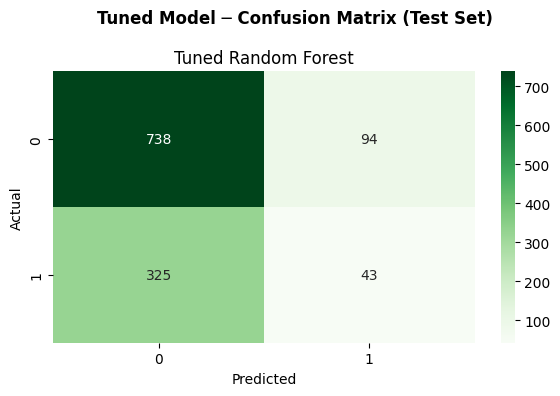

In [27]:
y_pred_rf_best = rf_best.predict(X_test_c)

print('=== Tuned Random Forest — Test Set ===')
print(f'  Estimators: {rf_best.n_estimators}')
print(f'  Max Depth : {rf_best.max_depth}')
print(f'  Min Samples Leaf: {rf_best.min_samples_leaf}')
print(classification_report(y_test_c, y_pred_rf_best, target_names=le_target.classes_))

# ── Confusion matrices ───────────────────────
fig, ax = plt.subplots(1, 1, figsize=(6, 4))
cm = confusion_matrix(y_test_c, y_pred_rf_best)
sns.heatmap(cm, annot=True, fmt='d', ax=ax, cmap='Greens')
ax.set_title('Tuned Random Forest')
ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
plt.suptitle('Tuned Model ─ Confusion Matrix (Test Set)',
             fontweight='bold')
plt.tight_layout(); plt.show()

Classification Comparison

In [28]:
results_clf = pd.DataFrame({
    'Model': [
        'Decision Tree (Baseline)',
        'Random Forest (Default)',
        'Random Forest (Tuned)'
    ],
    'Accuracy': [
        accuracy_score(y_test_c, y_pred_dt),
        accuracy_score(y_test_c, y_pred_rf),
        accuracy_score(y_test_c, y_pred_rf_best)
    ],
    'Precision (w)': [
        precision_score(y_test_c, y_pred_dt, average='weighted'),
        precision_score(y_test_c, y_pred_rf, average='weighted'),
        precision_score(y_test_c, y_pred_rf_best, average='weighted')
    ],
    'Recall (w)': [
        recall_score(y_test_c, y_pred_dt, average='weighted'),
        recall_score(y_test_c, y_pred_rf, average='weighted'),
        recall_score(y_test_c, y_pred_rf_best, average='weighted')
    ],
    'F1 (weighted)': [
        f1_score(y_test_c, y_pred_dt, average='weighted'),
        f1_score(y_test_c, y_pred_rf, average='weighted'),
        f1_score(y_test_c, y_pred_rf_best, average='weighted')
    ],
    'CV F1 Mean': [
        cv_dt.mean(),
        cv_rf.mean(),
        gs_rf.best_score_
    ],
    'CV F1 Std': [
        cv_dt.std(),
        cv_rf.std(),
        gs_rf.cv_results_['std_test_score'][gs_rf.best_index_]
    ]
}).set_index('Model').round(4)
print(results_clf.to_string())

                          Accuracy  Precision (w)  Recall (w)  F1 (weighted)  CV F1 Mean  CV F1 Std
Model                                                                                              
Decision Tree (Baseline)    0.5633         0.5768      0.5633         0.5695      0.5607     0.0105
Random Forest (Default)     0.6367         0.5679      0.6367         0.5861      0.5904     0.0127
Random Forest (Tuned)       0.6508         0.5776      0.6508         0.5923      0.5968     0.0095


In [29]:
bruteforce_results = pd.DataFrame({
    'Model': ['Decision Tree (Baseline)', 'Random Forest (Default)', 'Random Forest (Tuned)'],
    'BF Precision': [
        precision_score(y_test_c, y_pred_dt, pos_label=1),
        precision_score(y_test_c, y_pred_rf, pos_label=1),
        precision_score(y_test_c, y_pred_rf_best, pos_label=1)
    ],
    'BF Recall': [
        recall_score(y_test_c, y_pred_dt, pos_label=1),
        recall_score(y_test_c, y_pred_rf, pos_label=1),
        recall_score(y_test_c, y_pred_rf_best, pos_label=1)
    ],
    'BF F1': [
        f1_score(y_test_c, y_pred_dt, pos_label=1),
        f1_score(y_test_c, y_pred_rf, pos_label=1),
        f1_score(y_test_c, y_pred_rf_best, pos_label=1)
    ],
    'False Negatives': [
        ((y_test_c==1) & (y_pred_dt==0)).sum(),
        ((y_test_c==1) & (y_pred_rf==0)).sum(),
        ((y_test_c==1) & (y_pred_rf_best==0)).sum()
    ]
}).set_index('Model').round(4)
print(bruteforce_results.to_string())

                          BF Precision  BF Recall   BF F1  False Negatives
Model                                                                     
Decision Tree (Baseline)        0.3098     0.3451  0.3265              241
Random Forest (Default)         0.2901     0.1277  0.1774              321
Random Forest (Tuned)           0.3139     0.1168  0.1703              325


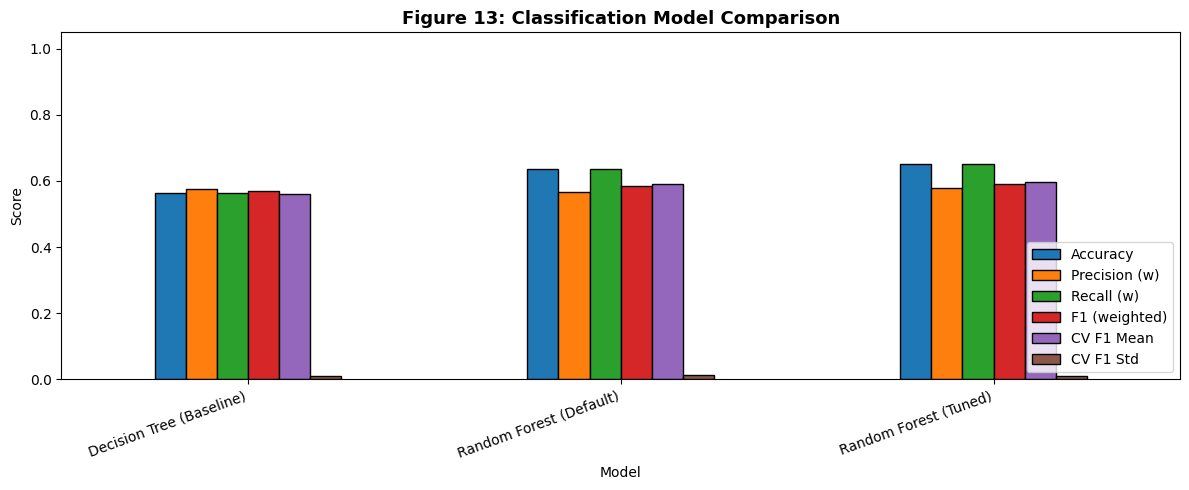

In [30]:
# ── Bar Chart — Classification Metrics ──
results_clf.plot(kind='bar', figsize=(12, 5), edgecolor='black')
plt.title('Figure 13: Classification Model Comparison', fontsize=13, fontweight='bold')
plt.ylabel('Score')
plt.ylim(0, 1.05)
plt.xticks(rotation=20, ha='right')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('fig13_cls_model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

## Regression – Predicting `avg_packet_size`

In [32]:
# Drop the 'attack_category' from the features for regression
# And ensure 'avg_packet_size' is not in feature_cols if it's the target

reg_feature_cols = [c for c in feature_cols if c not in ['avg_packet_size']]

X_reg = X_scaled[reg_feature_cols]
y_reg = df_clean['avg_packet_size'].values

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42)

print(f"Regression Training features shape: {X_train_r.shape}")
print(f"Regression Testing features shape: {X_test_r.shape}")
print(f"Regression Training target shape: {y_train_r.shape}")
print(f"Regression Testing target shape: {y_test_r.shape}")
print(f"Target `avg_packet_size`: min={y_reg.min():.1f}, max={y_reg.max():.1f}, mean={y_reg.mean():.1f}, std={y_reg.std():.1f}")

Regression Training features shape: (4800, 18)
Regression Testing features shape: (1200, 18)
Regression Training target shape: (4800,)
Regression Testing target shape: (1200,)
Target `avg_packet_size`: min=199.0, max=375.4, mean=292.0, std=23.3


### Baseline – Linear Regression

In [33]:
lr = LinearRegression()
lr.fit(X_train_r, y_train_r)
y_pred_lr = lr.predict(X_test_r)
cv_lr = cross_val_score(lr, X_reg, y_reg, cv=5, scoring='r2')

print("=== Linear Regression (Baseline) ===")
print(f"MAE:  {mean_absolute_error(y_test_r, y_pred_lr):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test_r, y_pred_lr)):.4f}")
print(f"R2:   {r2_score(y_test_r, y_pred_lr):.4f}")
print(f"CV R2: mean={cv_lr.mean():.4f}, std={cv_lr.std():.4f}")

=== Linear Regression (Baseline) ===
MAE:  15.5046
RMSE: 25.4684
R2:   -0.2002
CV R2: mean=0.1922, std=0.1655


### Improved – Ridge Regression (L2 regularisation)

In [35]:
ridge = Ridge(alpha=1.0, random_state=42)
ridge.fit(X_train_r, y_train_r)
y_pred_ridge = ridge.predict(X_test_r)
cv_ridge = cross_val_score(ridge, X_reg, y_reg, cv=5, scoring='r2')

print("=== Ridge Regression (Improved) ===")
print(f"MAE:  {mean_absolute_error(y_test_r, y_pred_ridge):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test_r, y_pred_ridge)):.4f}")
print(f"R2:   {r2_score(y_test_r, y_pred_ridge):.4f}")
print(f"CV R2: mean={cv_ridge.mean():.4f}, std={cv_ridge.std():.4f}")

=== Ridge Regression (Improved) ===
MAE:  15.5043
RMSE: 25.4506
R2:   -0.1986
CV R2: mean=0.1924, std=0.1650


### Grid Search – Ridge Regression

In [37]:
param_grid_ridge = {
    'alpha': [0.1, 1.0, 10.0, 100.0, 1000.0]
}

gs_ridge = GridSearchCV(
    Ridge(random_state=42), # Add random_state for reproducibility
    param_grid_ridge,
    cv=5,
    scoring='r2',         # optimise for R2
    n_jobs=-1,
    return_train_score=True
)
gs_ridge.fit(X_train_r, y_train_r)

print('=== Ridge Regression — GridSearchCV Results ===')
print('Best parameters:', gs_ridge.best_params_)
print('Best CV R2:     ', round(gs_ridge.best_score_, 4))

# Show top 5 configurations
cv_df_ridge = pd.DataFrame(gs_ridge.cv_results_)[['param_alpha',
     'mean_test_score','std_test_score','mean_train_score']]
cv_df_ridge = cv_df_ridge.sort_values('mean_test_score', ascending=False).head(5)
cv_df_ridge = cv_df_ridge.round(4)
print('\nTop 5 configurations:')
print(cv_df_ridge.to_string(index=False))

# Overfitting check: train score vs test score for each config
print('\nNote: if mean_train_score >> mean_test_score -> overfitting')

# Store best Ridge model
ridge_best = gs_ridge.best_estimator_

=== Ridge Regression — GridSearchCV Results ===
Best parameters: {'alpha': 10.0}
Best CV R2:      0.3064

Top 5 configurations:
 param_alpha  mean_test_score  std_test_score  mean_train_score
        10.0           0.3064          0.0505            0.3162
         1.0           0.3062          0.0516            0.3162
         0.1           0.3062          0.0517            0.3162
       100.0           0.3039          0.0433            0.3122
      1000.0           0.2469          0.0281            0.2527

Note: if mean_train_score >> mean_test_score -> overfitting


### Tuned Ridge Regression Performance Visualization

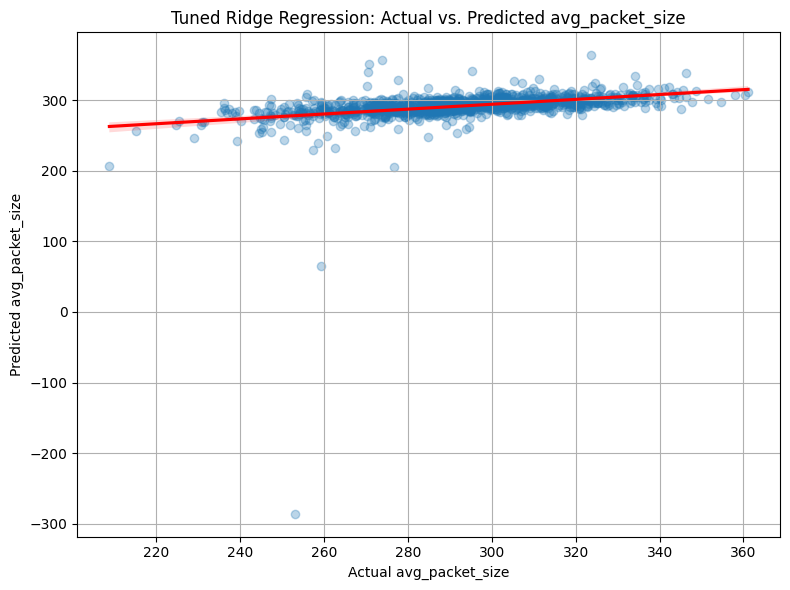

In [39]:
y_pred_ridge_best = ridge_best.predict(X_test_r)

plt.figure(figsize=(8, 6))
sns.regplot(x=y_test_r, y=y_pred_ridge_best, scatter_kws={'alpha':0.3}, line_kws={'color':'red'})
plt.title('Tuned Ridge Regression: Actual vs. Predicted avg_packet_size')
plt.xlabel('Actual avg_packet_size')
plt.ylabel('Predicted avg_packet_size')
plt.grid(True)
plt.tight_layout()
plt.show()

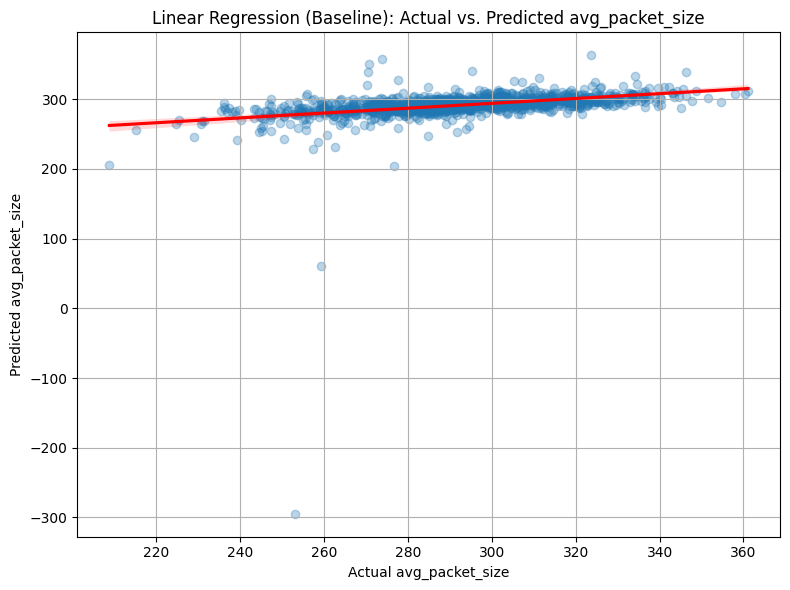

In [42]:
plt.figure(figsize=(8, 6))
sns.regplot(x=y_test_r, y=y_pred_lr, scatter_kws={'alpha':0.3}, line_kws={'color':'red'})
plt.title('Linear Regression (Baseline): Actual vs. Predicted avg_packet_size')
plt.xlabel('Actual avg_packet_size')
plt.ylabel('Predicted avg_packet_size')
plt.grid(True)
plt.tight_layout()
plt.show()

### Regression Model Comparison

In [40]:
results_reg = pd.DataFrame({
    'Model': [
        'Linear Regression (Baseline)',
        'Ridge Regression (Default)',
        'Ridge Regression (Tuned)'
    ],
    'MAE': [
        mean_absolute_error(y_test_r, y_pred_lr),
        mean_absolute_error(y_test_r, y_pred_ridge),
        mean_absolute_error(y_test_r, y_pred_ridge_best)
    ],
    'RMSE': [
        np.sqrt(mean_squared_error(y_test_r, y_pred_lr)),
        np.sqrt(mean_squared_error(y_test_r, y_pred_ridge)),
        np.sqrt(mean_squared_error(y_test_r, y_pred_ridge_best))
    ],
    'R2': [
        r2_score(y_test_r, y_pred_lr),
        r2_score(y_test_r, y_pred_ridge),
        r2_score(y_test_r, y_pred_ridge_best)
    ],
    'CV R2 Mean': [
        cv_lr.mean(),
        cv_ridge.mean(),
        gs_ridge.best_score_
    ],
    'CV R2 Std': [
        cv_lr.std(),
        cv_ridge.std(),
        gs_ridge.cv_results_['std_test_score'][gs_ridge.best_index_]
    ]
}).set_index('Model').round(4)

print(results_reg.to_string())

                                  MAE     RMSE      R2  CV R2 Mean  CV R2 Std
Model                                                                        
Linear Regression (Baseline)  15.5046  25.4684 -0.2002      0.1922     0.1655
Ridge Regression (Default)    15.5043  25.4506 -0.1986      0.1924     0.1650
Ridge Regression (Tuned)      15.5016  25.2941 -0.1839      0.3064     0.0505


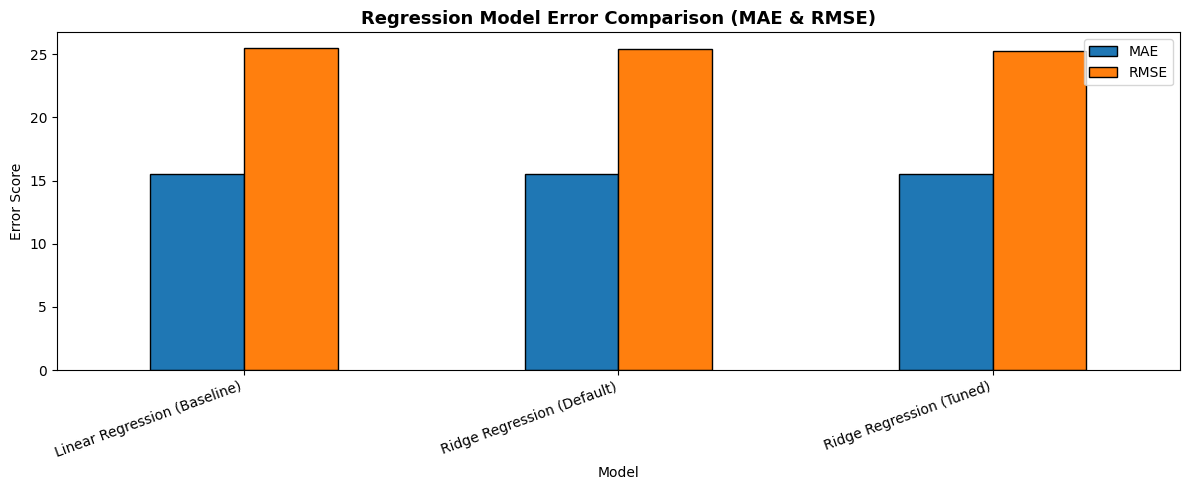

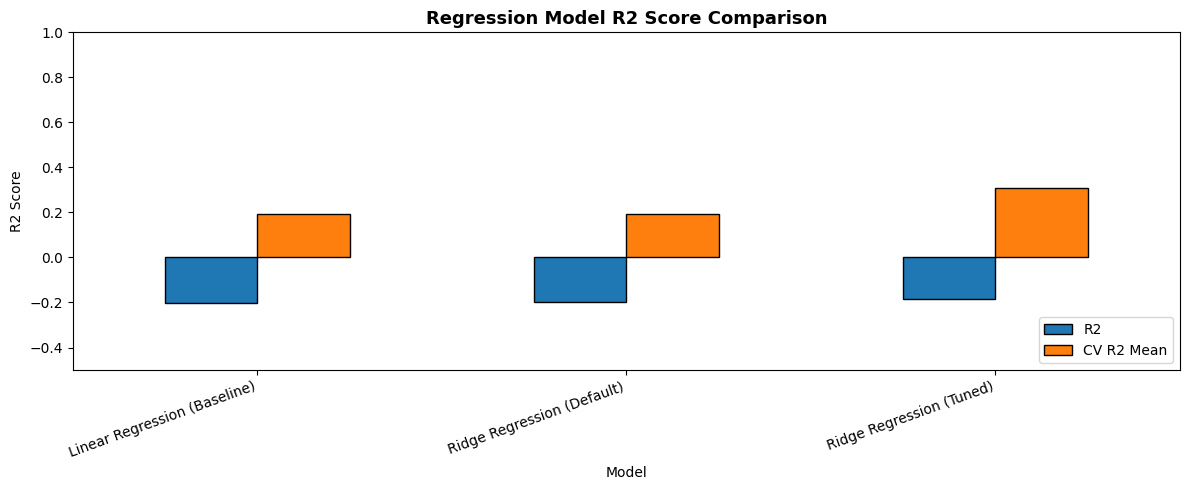

In [41]:
# ── Bar Chart — Regression Metrics ──
results_reg[['MAE', 'RMSE']].plot(kind='bar', figsize=(12, 5), edgecolor='black')
plt.title('Regression Model Error Comparison (MAE & RMSE)', fontsize=13, fontweight='bold')
plt.ylabel('Error Score')
plt.xticks(rotation=20, ha='right')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

results_reg[['R2', 'CV R2 Mean']].plot(kind='bar', figsize=(12, 5), edgecolor='black')
plt.title('Regression Model R2 Score Comparison', fontsize=13, fontweight='bold')
plt.ylabel('R2 Score')
plt.ylim(-0.5, 1.0)
plt.xticks(rotation=20, ha='right')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

## Key Findings
- Best overall accuracy: Tuned Random Forest (65%)
- Best BruteForce F1: Decision Tree Baseline (0.33)
- Class imbalance remains the core unresolved challenge
- 88% of BruteForce attacks go undetected in the best model
- Future work: SMOTE, XGBoost, threshold tuning